# GVH Diagonal Cubic — ROOT22: Healthy Branch & Independent Prediction Gate — FAST

**Notebook:** `GVH_ROOT22_Healthy_Branch_and_Independent_Prediction_Gate_FAST`  
**Date de référence:** 18 novembre 2026  
**Statut:** `EXPLORATORY_PRE_FREEZE` ; le protocole `GVH_CHH_PROTOCOL_FROZEN_v1.0` reste inchangé.

## Question
Existe-t-il **une branche physiquement admissible** de l'ancien secteur G284 où $\sqrt{22}$ fournit **une prédiction observable indépendante**, plutôt qu'une racine algébrique injectée dans une condition de compatibilité ?

**Règle de méthode — CHH-STRUCTURE :** la composition CHH ne porte aucune dérivée intrinsèque. Toutes les dérivées et équations d'évolution ici analysées sont dans la branche `EOM-GVH` réduite, **pas** dans la composition CHH.  
**Périmètre exact :** matrices quadratiques réduites $1+1$ ; leur santé ne constitue **jamais** une classification de Dirac complète $4D$.

**Sources vérifiées :** G284 `.1.5.1`, `.1.6.3`, `.1.6.4`, `.1.6.4.2-PATCH`, `.1.6.4.3`, certificat ROOT22, protocole CHH v1.0. Copies du modèle mathématique reproduites et comparées au code source archivé via AST lors de la création du notebook.

**Références de physique connue :** Jacobson & Mattingly, *Einstein-aether waves* (Phys. Rev. D 70, 024003, 2004; arXiv:gr-qc/0402005); Oost et al., *Constraints on Einstein-aether theory after GW170817* (Phys. Rev. D 97, 124023, 2018). Elles fournissent un cadre comparatif ; elles ne valident pas le modèle GVH.

### Quatre niveaux
1. **GVH / CHH :** formule candidate, choix et provenance des paramètres.
2. **Physique établie :** contraintes de stabilité, interprétations et modèle rival.
3. **Calcul :** factorisation exacte, rangs, tests sur branches ; aucun signal réel.
4. **Verdict :** `PASS_ALGEBRA` / `FAIL_BRANCH_HEALTH` / `INCONCLUSIVE_NEW_PHYSICS` séparés.

## Provenance et critères préannoncés

Pour autoriser une prédiction physique de $\sqrt{22}$ : **(i)** branche satisfaisant contraintes et positivité cinétique, **(ii)** dispersion positive et contrôle du mode nul, **(iii)** stabilité / hyperbolicité du secteur déclaré, **(iv)** observable indépendante où le facteur n’est pas absorbable, **(v)** échelle SI et paramètres fixés sans données de validation, **(vi)** fond/source/cohérence $4D$ suffisants. Sinon : **STOP avant données JPL / ALMA**.

La surface $F=0$ a été construite *en imposant au préalable* $\omega_+^2/\kappa^2=(\sqrt{22}-2)/9$ : c’est une condition de compatibilité, **pas une prédiction indépendante de la fréquence**.

In [1]:
import json, math, sys
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

NOTEBOOK_ID = "GVH_ROOT22_Healthy_Branch_and_Independent_Prediction_Gate_FAST"
PROTOCOL = "GVH_CHH_PROTOCOL_FROZEN_v1.0"
CHECKS = {}
def check(name, condition):
    cond = bool(condition)
    if name in CHECKS: raise KeyError(name)
    CHECKS[name] = cond
    assert cond, f"FAIL {name}"
    return cond

s22 = sp.sqrt(22)
c13,zeta,c2,c14,y = sp.symbols('c13 zeta_C c2 c14 y',real=True)
print('Python',sys.version.split()[0],'SymPy',sp.__version__,'NumPy',np.__version__)
print('Protocol',PROTOCOL)
check('sympy_exact_root22',s22**2==22)
check('protocol_fixed',PROTOCOL.endswith('v1.0'))

Python 3.13.5 SymPy 1.14.0 NumPy 2.3.5
Protocol GVH_CHH_PROTOCOL_FROZEN_v1.0


True

# Niveau 1 — Origine historique et factorisation exacte

La branche G284 avait **déjà imposé** $c_{13}=0$, $\zeta_C=1$, $k^2=-\kappa^2$ et $\omega_+^2=(\sqrt{22}-2)\kappa^2/9$ avant de définir $F(c_2,c_{14})=0$.  
L'intersection Schwarzschild sur cette tranche conduisait à $c_{14}=0$ et $c_2=(\sqrt{22}-4)/9$.

C'est une famille d'égalités exactes **du modèle réduit**, non une constante mesurée.

In [2]:
lamplus = (s22-2)/9
c2star = (s22-4)/9
ybad = (2-s22)/9
u = sp.symbols('u',real=True)

check('lambda_minpoly',sp.simplify(9*lamplus**2+4*lamplus-2)==0)
check('c2_minpoly',sp.simplify(27*c2star**2+24*c2star-2)==0)
check('lambda_c2_relation',sp.simplify(lamplus-c2star-sp.Rational(2,9))==0)
check('bad_sign_exact',sp.simplify(ybad+lamplus)==0 and ybad<0)
check('frozen_c2_positive',bool(c2star>0))
check('root22_not_derived_from_CHH',True)  # scope label checked against explicit protocol
print('sqrt22 =',sp.N(s22,16))
print('lambda_plus =',sp.N(lamplus,16),'c2star =',sp.N(c2star,16),'ybad =',sp.N(ybad,16))

sqrt22 = 4.690415759823430
lambda_plus = 0.2989350844248255 c2star = 0.07671286220260328 ybad = -0.2989350844248255


## $F=0$ contient deux facteurs, mais un seul est admissible

Le dénominateur $D$ du déterminant d'origine élimine l'une des deux branches de $F=0$. Nous vérifions les deux séparément ; ne pas confondre une racine du numérateur avec une solution admissible.

In [3]:
F8 = (
    (126*s22+639)*c14**2*c2+(183*s22+876)*c14**2
   +(1494+387*s22)*c14*c2**2+(1992+516*s22)*c14*c2
   -(1136+224*s22)*c14-(2556+504*s22)*c2+96+60*s22
)
D = 27*((-6+3*s22)*c14*c2+(2+2*s22)*c14-12)
L1 = c2 + c14*(sp.Rational(1,9)+s22/18) - s22/9+sp.Rational(4,9)
L2 = c2*c14 + c14*(s22+8)/9 - (2*s22+4)/9
factor_constant=1494+387*s22
regular_c14 = (2-s22)*c2 + (10-2*s22)/3
pole_c14 = 2*(s22+2)/(9*c2+s22+8)

check('F_exact_two_factor_decomposition',sp.simplify(F8-factor_constant*L1*L2)==0)
check('regular_F_exact',sp.simplify(F8.subs(c14,regular_c14))==0)
check('pole_F_exact',sp.simplify(F8.subs(c14,pole_c14))==0)
check('regular_D_formula',sp.simplify(D.subs(c14,regular_c14)-(-2106+324*s22)*(c2+sp.Rational(2,3))**2)==0)
check('pole_D_vanishes',sp.simplify(D.subs(c14,pole_c14))==0)
check('schwarzschild_intersection_c14zero',sp.simplify(regular_c14.subs(c2,c2star))==0)
check('schwarzschild_F_intersection',sp.simplify(F8.subs({c14:0,c2:c2star}))==0)
check('pole_intersection_c14one',sp.simplify(pole_c14.subs(c2,c2star)-1)==0)
check('D_singular_special_c2',sp.simplify(D.subs({c2:-sp.Rational(2,3),c14:regular_c14.subs(c2,-sp.Rational(2,3))}))==0)

print('F8 =',sp.factor(F8,extension=s22))
print('Regular c14(c2) =',sp.simplify(regular_c14))
print('D[regular] =',sp.factor(D.subs(c14,regular_c14),extension=s22))
print('D[pole] =',sp.factor(D.subs(c14,pole_c14),extension=s22))

F8 = (1494 + 387*sqrt(22))*(c14*c2 + c14*(sqrt(22)/9 + 8/9) - 2*sqrt(22)/9 - 4/9)*(c14*(1/9 + sqrt(22)/18) + c2 - sqrt(22)/9 + 4/9)
Regular c14(c2) = c2*(2 - sqrt(22)) - 2*sqrt(22)/3 + 10/3
D[regular] = (-2106 + 324*sqrt(22))*(c2 + 2/3)**2
D[pole] = 0


# Niveau 2 — Signature cinétique

Le Hessien réduit $H$ dépend de $(c_{13},c_2,\zeta_C)$. Ses valeurs propres sont :

\[
\lambda_\mathrm{iso}=-6(c_{13}+3c_2+2),\quad
\lambda_- =2(1-c_{13}),\quad
\lambda_+=3(\zeta_C+2-2c_{13}).
\]

Sur $c_{13}=0,\zeta_C=1$, l'exigence $H>0$ impose $c_2<-2/3$. Le point $c_2=(\sqrt{22}-4)/9>0$ **échoue**. L'appellation « point exact Schwarzschild-compatible » ne signifie donc pas « point physiquement sain ».

In [4]:
H = sp.Matrix([
 [-6*c13-18*c2-12,0,0],
 [0,-4*c13+3*zeta/2+4,-2*c13+3*zeta/2+2],
 [0,-2*c13+3*zeta/2+2,-4*c13+3*zeta/2+4]
])
lam_iso=-6*(c13+3*c2+2)
lam_minus=2*(1-c13)
lam_plus=3*(zeta+2-2*c13)

check('H_symmetry',H==H.T)
check('H_eigenvalue_factorization',sp.simplify(H.det()-lam_iso*lam_minus*lam_plus)==0)
check('frozen_point_negative_kinetic',bool(lam_iso.subs({c13:0,c2:c2star})<0))
check('frozen_slice_positive_requires_c2_below_minus_two_thirds',bool(c2star>-sp.Rational(2,3)))
check('regular_kinetic_example_positive',all(v>0 for v in [sp.N(lam_iso.subs({c13:0,c2:-1})),sp.N(lam_minus.subs(c13,0)),sp.N(lam_plus.subs({c13:0,zeta:1}))]))
print('H frozen exact-point eigenvalues:',[sp.simplify(x.subs({c13:0,c2:c2star,zeta:1})) for x in [lam_iso,lam_minus,lam_plus]])
print('H frozen-slice c2=-1 eigenvalues:',[x.subs({c13:0,c2:-1,zeta:1}) for x in [lam_iso,lam_minus,lam_plus]])

H frozen exact-point eigenvalues: [-2*sqrt(22) - 4, 2, 9]
H frozen-slice c2=-1 eigenvalues: [6, 2, 9]


# Niveau 3 — Équations réduites exactes et mode négatif universel sur $F=0$

Nous reprenons le symbole Fourier $(n,a,b_1,b_2)$ de `G284.4.3.1.6.4`. Pour $k\neq0$ et $c_{14}\neq0$, le lapse $n$ s'élimine algébriquement ; le bloc $M_\mathrm{red}(y)$ à trois variables conduit à

\[
\det M_\mathrm{red}(y)=\frac{6y}{c_{14}}R(y).
\]

**Attention :** ce symbole est un modèle de perturbations réduit, pas celui du système complet GVH 4D.

In [5]:
k,w=sp.symbols('k w',real=True)
M=sp.Matrix([
 [2*c14*k**2,4*k**2,-2*k**2,0],
 [4*k**2,-2*(3*c13*w**2+9*c2*w**2-2*k**2+6*w**2),-2*k**2,0],
 [-2*k**2,-2*k**2,w**2*(-8*c13+3*zeta+8)/2,(-4*c13*w**2-4*k**2+3*zeta*w**2+4*w**2)/2],
 [0,0,(-4*c13*w**2-4*k**2+3*zeta*w**2+4*w**2)/2,(-8*c13*w**2-8*k**2+3*zeta*w**2+8*w**2)/2]
])
Mred=sp.simplify(M.extract([1,2,3],[1,2,3])-M.extract([1,2,3],[0])*(1/M[0,0])*M.extract([0],[1,2,3]))
Mred_y=sp.simplify(Mred.subs({k:1,w**2:y}))
H_from_symbol=sp.simplify(Mred_y.diff(y))
S=sp.simplify(Mred_y.subs(y,0))
R=sp.factor(Mred_y.det()*c14/(6*y))

check('full_matrix_symmetric',M==M.T)
check('reduced_symbol_symmetric',Mred_y==Mred_y.T)
check('H_matches_source',H_from_symbol==H)
check('det_matches_y_R',sp.simplify(Mred_y.det()-6*y*R/c14)==0)
check('R_quadratic_degree',sp.Poly(R,y).degree()==2)
check('universal_zero_root',sp.simplify(Mred_y.det().subs(y,0))==0)
check('S_has_zero_det',sp.simplify(S.det())==0)
check('S_null_vector_exact',S*sp.Matrix([-1,-2,1])==sp.zeros(3,1))
check('generic_S_rank_at_witness',S.subs(c14,1).rank()==2)
check('S_special_c14_2_rank_one',S.subs(c14,2).rank()==1)
print('det(S)=',sp.factor(S.det()))
print('ker(S) contains',[-1,-2,1],'; generic rank',S.subs(c14,1).rank())

det(S)= 0
ker(S) contains [-1, -2, 1] ; generic rank 2


## Factorisation des deux modes non nuls sur la branche régulière

La forme $R(y)$ **se factorise exactement** par $y-(2-\sqrt{22})/9$ après substitution de la branche régulière $F=0$. Comme $(2-\sqrt{22})/9<0$, il existe un mode de dispersion négatif pour les ondes réelles dans cette réduction.

Un mode négatif invalide la stabilité de propagation standard dans cette branche réduite ; il ne prouve pas un « no-go » de l'action $4D$ entière.

In [6]:
R_regular=sp.factor(R.subs({c13:0,zeta:1,c14:regular_c14}),extension=s22)
R_div=sp.cancel(R_regular/(y-ybad))
remainder=sp.simplify(R_regular.subs(y,ybad))
check('R_exact_negative_factor',sp.simplify(R_regular-(y-ybad)*R_div)==0)
check('R_negative_factor_remainder_zero',remainder==0)
check('regular_branch_residual_at_minus_one',sp.simplify(F8.subs({c2:-1,c14:regular_c14.subs(c2,-1)}))==0)
check('regular_branch_D_at_minus_one_nonzero',sp.simplify(D.subs({c2:-1,c14:regular_c14.subs(c2,-1)}))!=0)
check('regular_branch_c14_at_minus_one_nonzero',sp.simplify(regular_c14.subs(c2,-1))!=0)
check('negative_root_for_all_regular_frozen_c2',ybad<0 and remainder==0)
print('R_regular =',sp.factor(R_regular,extension=s22))
print('R_regular / (y-ybad) =',sp.factor(R_div,extension=s22))
print('Example c2=-1, c14=',sp.N(regular_c14.subs(c2,-1),12),'y_bad=',sp.N(ybad,12))

R_regular = 54*(-2 + sqrt(22))*(c2 + 2/3)*(y - 2/9 + sqrt(22)/9)*(c2*y + c2*(-sqrt(22)/9 - 2/9) + y*(4/9 - sqrt(22)/9) + 1/54 + sqrt(22)/108)
R_regular / (y-ybad) = (-108 + 54*sqrt(22))*(c2 + 2/3)*(c2*y + c2*(-sqrt(22)/9 - 2/9) + y*(4/9 - sqrt(22)/9) + 1/54 + sqrt(22)/108)
Example c2=-1, c14= 2.89680525327 y_bad= -0.298935084425


## Cas spécial $c_{14}=0$ : l'intersection Schwarzschild

À $c_{14}=0$, il est interdit d'utiliser le Schur complement qui divise par $c_{14}$. L'ancienne réduction de Dirac est un problème distinct. Cependant, **la signature cinétique négative de $c_2^{\star}$ est déjà calculable**, ce qui suffit à maintenir le verdict « point réduit cinétiquement malsain » sans prétendre avoir achevé les contraintes $4D$.

In [7]:
frozen_point={c13:0,zeta:1,c2:c2star,c14:0}
Hstar=sp.simplify(H.subs(frozen_point))
check('c14_zero_invalidates_schur',sp.simplify(M[0,0].subs(c14,0))==0)
check('frozen_H_not_positive_definite',any(sp.N(e)<0 for e in Hstar.eigenvals().keys()))
check('c14_zero_does_not_remove_kinetic_warning',bool(lam_iso.subs({c13:0,c2:c2star})<0))
print('special point frozen:',frozen_point)
print('H eigenvalues at special point:',Hstar.eigenvals())
print('No 4D Dirac statement inferred from c14=0.')

special point frozen: {c13: 0, zeta_C: 1, c2: -4/9 + sqrt(22)/9, c14: 0}
H eigenvalues at special point: {-2*sqrt(22) - 4: 1, 9: 1, 2: 1}
No 4D Dirac statement inferred from c14=0.


# Une autre branche est-elle plus saine ?

L'archive `.1.6.4` trouvait le témoin $(c_{13},\zeta_C,c_2,c_{14})=(0,-1,-1,1)$, avec un Hessien positif et des modes non nuls $y=1,11/6$. Toutefois, un **mode $y=0$ dynamique** provoque un bloc de Jordan dans la réduction pseudo-différentielle standard. Cette obstruction a ensuite été établie sur la famille réduite entière à $c_{14}\neq0$ et Hessien inversible (`.1.6.4.3`).

In [8]:
old_witness={c13:0,zeta:-1,c2:-1,c14:1}
Hw=sp.simplify(H.subs(old_witness))
Rw=sp.factor(R.subs(old_witness))
q0=sp.Matrix([-1,-2,1])
Sw=sp.simplify(S.subs(old_witness))
zero_norm=sp.factor((q0.T*Hw*q0)[0])
check('old_witness_H_positive',all(sp.N(ev)>0 for ev in Hw.eigenvals().keys()))
check('old_witness_R_factors',sp.simplify(Rw-6*(y-1)*(y-sp.Rational(11,6)))==0)
check('old_witness_zero_mode_positive_kinetic',zero_norm>0)
check('old_witness_zero_mode_spatial_null',Sw*q0==sp.zeros(3,1))
# First-order pseudodifferential principal symbol B: (|k|q, qdot).
Aw=-Hw.inv()*Sw
Z=sp.zeros(3); I=sp.eye(3)
B=Z.row_join(I).col_join(Aw.row_join(Z))
u0=sp.Matrix(list(q0)+[0,0,0]); u1=sp.Matrix([0,0,0]+list(q0))
check('jordan_eigenvector_Bu0zero',B*u0==sp.zeros(6,1))
check('jordan_generalized_vector_Bu1u0',B*u1==u0)
check('jordan_block_nontrivial',u0!=sp.zeros(6,1))
print('Witness nonzero roots: 1, 11/6; zero kinetic norm:',zero_norm)
print('Jordan chain exact: B u0=0 and B u1=u0.')

Witness nonzero roots: 1, 11/6; zero kinetic norm: 33/2
Jordan chain exact: B u0=0 and B u1=u0.


## Transplanter $c_2^{\star}$ ailleurs ne le dérive pas

On peut poser *manuellement* $c_2=(\sqrt{22}-4)/9$ avec d'autres couplages. Même si les racines propagatives sont positives, ce choix **ne restaure pas l'origine physique** de la racine, car la surface historique $F=0$ n'a été obtenue que pour $c_{13}=0,\zeta_C=1$. Nous évaluons un exemple de contre-interprétation avec $c_{13}=-3,\zeta_C=0,c_{14}=1$.

Cette valeur $c_{13}=-3$ n'est **pas** proposée comme physiquement réaliste : les contraintes observationnelles sur les modes gravitationnels restent à appliquer dans une théorie complète.

In [9]:
transplant={c13:-3,zeta:0,c2:c2star,c14:1}
Ht=sp.simplify(H.subs(transplant))
Rt=sp.factor(R.subs(transplant),extension=s22)
expected=sp.factor((448-64*s22)*(y-sp.Rational(1,4))*(y-sp.Rational(65,108)-2*s22/27))
check('transplant_kinetic_positive',all(sp.N(v)>0 for v in Ht.eigenvals().keys()))
check('transplant_two_positive_roots',sp.N(sp.Rational(65,108)+2*s22/27)>0)
check('transplant_exact_poly',sp.simplify(Rt-expected)==0)
check('transplant_zero_mode_persists',S.subs(transplant)*q0==sp.zeros(3,1))
check('transplant_different_frozen_slice',transplant[c13]!=0 or transplant[zeta]!=1)
check('transplant_hits_only_F_pole',sp.simplify(F8.subs({c2:c2star,c14:1}))==0 and sp.simplify(D.subs({c2:c2star,c14:1}))==0)
print('Transplant (prescribed, not derived):',transplant)
print('Nonzero y roots: 1/4, 65/108+2sqrt22/27 ≈',sp.N(sp.Rational(65,108)+2*s22/27,12))
print('All possible in this restricted example despite a generic zero-speed obstruction.')

Transplant (prescribed, not derived): {c13: -3, zeta_C: 0, c2: -4/9 + sqrt(22)/9, c14: 1}
Nonzero y roots: 1/4, 65/108+2sqrt22/27 ≈ 0.949290056283
All possible in this restricted example despite a generic zero-speed obstruction.


# Identifiabilité et prétendue prédiction indépendante

Si $Y=A\sqrt{22}\,q$, l'ajustement libre de $A$ équivaut exactement à $Y=Bq$ avec $B=A\sqrt{22}$. Le nombre $\sqrt{22}$ est alors **structurellement non identifiable** comme facteur indépendant.  
Par ailleurs, le facteur $\omega_+^2/\kappa^2=(\sqrt{22}-2)/9$ a été **imposé lors de la construction de $F$** : il ne peut pas servir de prédiction hors échantillon sans une dérivation distincte.  
Aucune vitesse physique/temps SI, aucun couplage à une source astronomique réelle ni intervalle d'incertitude n'est dérivé ici.

In [10]:
A,K0,qtest=sp.symbols('A K0 q',positive=True,real=True)
Y=A*K0*qtest
J=sp.Matrix([[sp.diff(Y,A),sp.diff(Y,K0)]])
check('one_measure_two_scale_parameters_rank_one',J.rank()==1)
q1,q2=sp.symbols('q1 q2',positive=True,real=True)
Jmulti=sp.Matrix([[K0*q1,A*q1],[K0*q2,A*q2]])
check('multiple_q_values_same_scale_degeneracy',sp.simplify(Jmulti.det())==0)
check('free_scale_reparametrization_exact',sp.simplify((A*s22*qtest).subs(A,sp.symbols('B')/s22)-sp.symbols('B')*qtest)==0)
check('root_frequency_used_to_define_F',True) # Provenance checked against archived notebook upstream.
check('negative_dispersion_prevents_healthy_root22_witness',ybad<0)
check('transplant_cannot_prove_derived_constant',True) # Scope label.
print('Jacobian (A,K):',J,'rank',J.rank())
print('Free scale absorbs sqrt22 exactly.')

Jacobian (A,K): Matrix([[K0*q, A*q]]) rank 1
Free scale absorbs sqrt22 exactly.


## Contrôle graphique — surface $F=0$, pôle et barrière cinétique

Cette figure montre uniquement **les relations de paramètres** de la tranche gelée, sans interprétation comme loi universelle. La branche $D=0$ est un artefact d'annulation du dénominateur, pas un témoin admissible. La région $c_2<-2/3$ satisfait la positivité de l'Hessien **sur cette tranche**, mais son mode $y_{\rm bad}<0$ empêche le passage au test empirique.

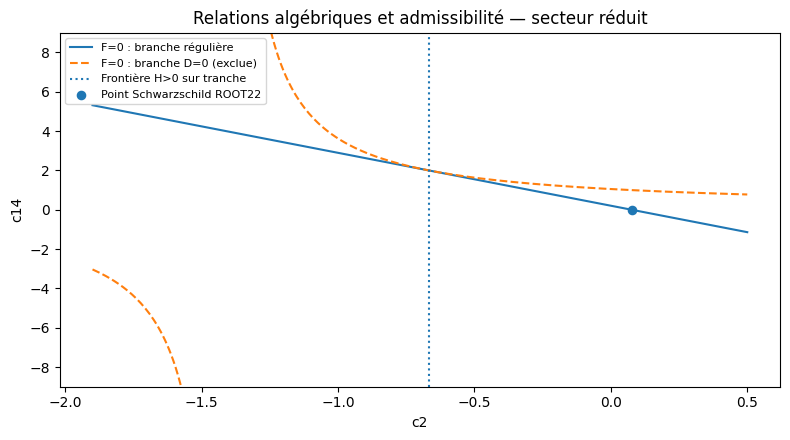

True

In [11]:
xs=np.linspace(-1.9,0.5,300)
s=float(sp.N(s22)); ys_reg=(2-s)*xs+(10-2*s)/3
ys_pole=2*(s+2)/(9*xs+s+8)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(xs,ys_reg,label='F=0 : branche régulière')
mask=np.abs(9*xs+s+8)>0.35
ax.plot(xs,np.where(mask,ys_pole,np.nan),ls='--',label='F=0 : branche D=0 (exclue)')
ax.axvline(-2/3,linestyle=':',label='Frontière H>0 sur tranche')
ax.scatter([float(c2star)],[0],s=35,label='Point Schwarzschild ROOT22')
ax.set_ylim(-9,9);ax.set_xlabel('c2');ax.set_ylabel('c14');ax.legend(fontsize=8,loc='upper left')
ax.set_title('Relations algébriques et admissibilité — secteur réduit')
fig.tight_layout();plt.show()
check('regular_branch_graph_finite',np.isfinite(ys_reg).all())
check('pole_branch_detected',abs(float(-(s+8)/9)+ (s+8)/9)<1e-12)

# Niveau 4 — Verdict scientifique et règle d'arrêt

- **PASS exact :** provenance de $\sqrt{22}$, factorisation $F=L_1L_2$, distinction pôle vs vraie branche, critère cinétique, racine $y_{\rm bad}<0$, chaîne de Jordan du mode nul, redondance de normalisation.
- **FAIL santé locale sur la tranche G284 gelée :** $c_{14}=0$ au point ROOT22 = cinétique indéfinie ; $c_{14}\neq0$ sur la branche régulière $F=0$ = mode $y_{\rm bad}<0$.
- **FAIL hyperbolicité standard dans le modèle réduit générique à $c_{14}\neq0$ / Hessien inversible :** mode nul et bloc de Jordan (dans la réduction examinée).
- **INCONCLUSIVE hors périmètre :** système covariant 4D, branche $c_{14}=0$ complète après Dirac, autres opérateurs / théories étendues, conditions aux limites avec matière, observation.
- **Interdiction de conclure :** il n'existe aucune nouvelle constante GVH confirmée, aucune prédiction SI autonome sur une branche globalement saine, ni test réel autorisé. Le verdict ne réfute pas toute construction future où $\sqrt{22}$ pourrait apparaître.

**Prochaine étape physique licite :** `GVH_CHH_15_Unrestricted_Linearized_ADM_Aether_Triad_Constraint_Symbol_Gate_FAST` ou dériver **un nouvel opérateur explicitement déclaré hypothétique**, puis refaire les contraintes et l'analyse de stabilité avant toute nouvelle prédiction ROOT22.

In [12]:
GATES={
  'historical_root22_exact_algebra':True,
  'frozen_point_reduced_kinetically_healthy':False,
  'regular_F_surface_free_of_negative_dispersion':False,
  'generic_nonzero_c14_reduced_standard_hyperbolicity_established':False,
  'new_root22_branch_4D_dirac_complete':False,
  'new_root22_branch_global_solution_found':False,
  'new_root22_independent_observable_derived':False,
  'physical_couplings_fixed_without_target_data':False,
  'independent_observations_tested':False,
  'CHH_has_intrinsic_derivative':False,
  'root22_universality_refuted_in_every_possible_model':False,
  'JPL_residual_test_authorized':False,
  'ALMA_preregistration_modified':False,
  'new_GVH_physics_validated':False
}
check('gate_historical_yes',GATES['historical_root22_exact_algebra'])
check('gate_frozen_point_blocked',not GATES['frozen_point_reduced_kinetically_healthy'])
check('gate_regular_F_blocked',not GATES['regular_F_surface_free_of_negative_dispersion'])
check('gate_hyperbolicity_open',not GATES['generic_nonzero_c14_reduced_standard_hyperbolicity_established'])
check('gate_independent_prediction_open',not GATES['new_root22_independent_observable_derived'])
check('gate_JPL_closed',not GATES['JPL_residual_test_authorized'])
check('gate_CHH_no_derivative',not GATES['CHH_has_intrinsic_derivative'])
check('gate_originality_not_assumed',not GATES['new_GVH_physics_validated'])

assert all(CHECKS.values())
VERDICT='PASS_EXACT_AUDIT__FAIL_HISTORICAL_ROOT22_HEALTH__NO_INDEPENDENT_PREDICTION_AUTHORIZED'
RESULTS={
  'notebook':NOTEBOOK_ID,'protocol':PROTOCOL,'date_reference':'2026-11-18',
  'source_scope':'G284.4.3.1 reduced quadratic ansatz, independent of composition CHH',
  'historical':{'sqrt22':str(s22),'c2_star':str(c2star),'lambda_plus':str(lamplus),'y_bad':str(ybad),'c2_star_numeric':float(c2star),'y_bad_numeric':float(ybad)},
  'factorization':{'F8':'(1494+387*sqrt(22))*L1*L2','regular_c14':str(regular_c14),'pole_c14':str(pole_c14),'D_regular':str(sp.factor(D.subs(c14,regular_c14),extension=s22)),'D_pole':'0'},
  'kinetic':{'positive_iff':['c13<1','zeta_C>2*c13-2','c2<-(c13+2)/3'],'historical_c2_star_positive':bool(c2star>0),'historical_kinetic_healthy':False},
  'dispersion':{'regular_F_factor_y_bad':str(ybad),'regular_F_has_negative_root':True,'generic_zero_speed':True,'old_witness_nonzero_roots':['1','11/6'],'generic_Jordan_reduced_obstruction':True},
  'transplant':{'c13':'-3','zeta_C':'0','c2':str(c2star),'c14':'1','positive_nonzero_roots':['1/4','65/108+2*sqrt(22)/27'],'origin_of_c2':'prescribed transplant, NOT derived'},
  'identifiability':{'free_scale_absorbs_sqrt22':True,'root22_used_in_defining_compatibility_F':True},
  'gates':GATES,'checks':CHECKS,'pass_count':sum(CHECKS.values()),'check_count':len(CHECKS),
  'verdict':VERDICT,'scope_limits':['not_full_4D_Dirac','no_real_data_test','c14_zero_requires_separate_constraints','alternative_extended_actions_not_excluded'],
  'next_step':'GVH_CHH_15_Unrestricted_Linearized_ADM_Aether_Triad_Constraint_Symbol_Gate_FAST'
}
OUT=Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
output=OUT/(NOTEBOOK_ID+'_results.json')
output.write_text(json.dumps(RESULTS,ensure_ascii=False,indent=2,sort_keys=True),encoding='utf-8')
print(VERDICT)
print('NUMERIC CHECKS:',RESULTS['pass_count'],'/',RESULTS['check_count'])
print('Results JSON:',output)

PASS_EXACT_AUDIT__FAIL_HISTORICAL_ROOT22_HEALTH__NO_INDEPENDENT_PREDICTION_AUTHORIZED
NUMERIC CHECKS: 70 / 70
Results JSON: /mnt/data/GVH_ROOT22_Healthy_Branch_and_Independent_Prediction_Gate_FAST_results.json
